# Práctica 2 — Introducción al aprendizaje supervisado

**Machine Learning · Máster Universitario en Inteligencia Artificial · curso 2026/2027**

Grupo: *4* · Integrantes: *Carlos Chapman Peña*, *Miguel Ángel Gordillo Masero*, *María Xiaolan Ríos Díaz*, *Pablo Sola Díaz*

---

Cuaderno **de partida**. La primera celda de código fija vuestro grupo y vuestra semilla y carga
los datos; la última escribe los dos ficheros que subís a Kaggle. **Entre medias, el cuaderno es
vuestro**: los títulos de los ejercicios solo marcan el orden. La interpretación va en celdas
Markdown, no en comentarios de Python.

## 0. Entorno, semilla y datos

Declarad `GRUPO` y `SEMILLA` antes de nada. **Toda la aleatoriedad del cuaderno sale de
`SEMILLA`**: las particiones de la validación, los desempates y cualquier `random_state`.

In [1]:
# --- Práctica 2: grupo, semilla, entorno y datos --------------------------------
GRUPO = 4        # vuestro número de grupo (entero)
SEMILLA = 67      # vuestra semilla (entero): toda la aleatoriedad sale de aquí

import os, sys, platform
import numpy as np, pandas as pd, matplotlib, sklearn, scipy
import matplotlib.pyplot as plt

assert isinstance(GRUPO, int) and isinstance(SEMILLA, int), "Declarad GRUPO y SEMILLA (enteros) antes de seguir."

DATOS = os.path.join("..", "Datos")                  # relativa a este cuaderno
sys.path.insert(0, os.path.join("..", "Codigo"))     # código proporcionado por el curso
from oner import OneRClassifier, OneRRegressor
from comprobar_estimador import comprobar_estimador

ciber_train = pd.read_csv(os.path.join(DATOS, "ciber_train.csv"))
ciber_test = pd.read_csv(os.path.join(DATOS, "ciber_test.csv"))
latencia_train = pd.read_csv(os.path.join(DATOS, "latencia_train.csv"))
latencia_test = pd.read_csv(os.path.join(DATOS, "latencia_test.csv"))

X_CIBER = [c for c in ciber_test.columns if c != "id"]          # características de ciber
X_LATENCIA = [c for c in latencia_test.columns if c != "id"]    # características de latencia

print("python      ", platform.python_version())
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("GRUPO       ", GRUPO, "· SEMILLA", SEMILLA)
print("ciber       ", ciber_train.shape, ciber_test.shape)
print("latencia    ", latencia_train.shape, latencia_test.shape)

python       3.14.8
numpy        2.5.3
pandas       3.0.6
scikit-learn 1.9.1
GRUPO        4 · SEMILLA 67
ciber        (5000, 13) (5000, 12)
latencia     (5000, 11) (3000, 10)


## Ejercicio 1. Cómo vais a medir

*(TODO)*

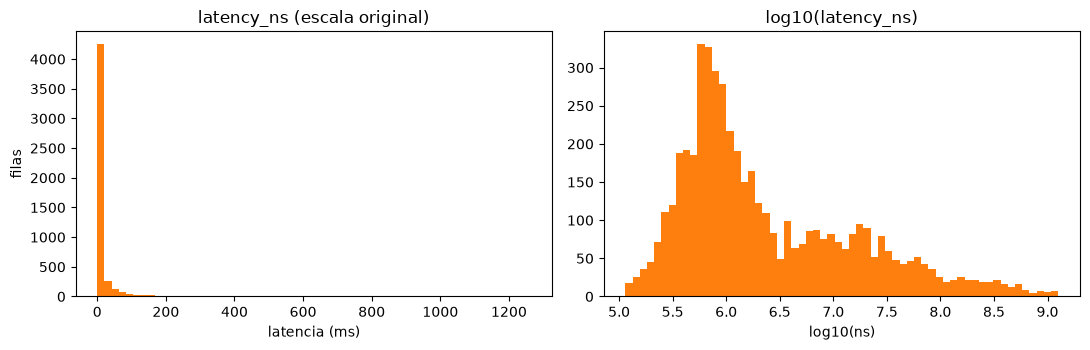

In [2]:
# Distribución de la variable objetivo (latencia_ns) en train
y = latencia_train["latency_ns"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(y / 1e6, bins=60, color="C1"); ax[0].set_title("latency_ns (escala original)")
ax[0].set_xlabel("latencia (ms)"); ax[0].set_ylabel("filas")
ax[1].hist(np.log10(y), bins=60, color="C1"); ax[1].set_title("log10(latency_ns)")
ax[1].set_xlabel("log10(ns)")
plt.tight_layout(); plt.show()

In [4]:
# Tipos de variables
display(latencia_train.dtypes)
# Información general
latencia_train.info()
# Valores ausentes
display(latencia_train.isnull().sum())
#No hay valores nulos. 
display(latencia_train.describe())

id                   str
block_size         int64
n_jobs             int64
iodepth            int64
read_fraction      int64
load_type            str
io_type              str
raid                 str
n_disks            int64
device_type          str
latency_ns       float64
dtype: object

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             5000 non-null   str    
 1   block_size     5000 non-null   int64  
 2   n_jobs         5000 non-null   int64  
 3   iodepth        5000 non-null   int64  
 4   read_fraction  5000 non-null   int64  
 5   load_type      5000 non-null   str    
 6   io_type        5000 non-null   str    
 7   raid           5000 non-null   str    
 8   n_disks        5000 non-null   int64  
 9   device_type    5000 non-null   str    
 10  latency_ns     5000 non-null   float64
dtypes: float64(1), int64(5), str(5)
memory usage: 555.9 KB


id               0
block_size       0
n_jobs           0
iodepth          0
read_fraction    0
load_type        0
io_type          0
raid             0
n_disks          0
device_type      0
latency_ns       0
dtype: int64

,block_size,n_jobs,iodepth,read_fraction,n_disks,latency_ns
count,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,208.576000,16.88100,16.934000,40.684000,17.994000,2.407129e+07
std,301.354501,15.54494,10.060412,36.357097,6.719598,9.319971e+07
min,4.000000,1.00000,1.000000,0.000000,3.000000,1.143315e+05
25%,16.000000,6.00000,8.000000,0.000000,12.000000,6.099692e+05
50%,64.000000,12.00000,15.000000,35.000000,20.000000,1.240523e+06
75%,256.000000,20.00000,27.000000,75.000000,24.000000,8.127825e+06
max,1024.000000,64.00000,32.000000,100.000000,24.000000,1.262194e+09


In [5]:
# cuánto varían las cinco ejecuciones de una misma configuración
# 1. Definir las columnas que representan la "configuración" (todas menos 'id' y 'latency_ns')
caracteristicas_config = [c for c in latencia_train.columns if c not in ['id', 'latency_ns']]

# 2. Agrupar por la configuración y contar cuántas filas (ejecuciones) tiene cada una
conteo_ejecuciones = latencia_train.groupby(caracteristicas_config).size()

print(f"Número total de configuraciones únicas: {len(conteo_ejecuciones)}")
print(f"¿Tienen todas exactamente 5 ejecuciones?: {(conteo_ejecuciones == 5).all()}")

# 3. Mostrar un ejemplo real de una configuración y sus 5 latencias distintas
# Buscamos una configuración que tenga 5 registros
primera_config = conteo_ejecuciones[conteo_ejecuciones == 5].index[0]

# Filtramos el dataset original para ver esas 5 filas
filtro = (latencia_train[caracteristicas_config] == primera_config).all(axis=1)
ejecuciones_muestra = latencia_train[filtro][['block_size', 'n_jobs', 'iodepth', 'read_fraction', 'load_type', 'io_type', 'raid', 'n_disks', 'device_type', 'latency_ns']]

print("\nEjemplo de las 5 ejecuciones para una misma configuración de hardware/carga:")
display(ejecuciones_muestra)

# 4. Calcular el desvío (desviación estándar y ratio máximo/mínimo) en esas 5 ejecuciones
latencias = ejecuciones_muestra['latency_ns']
print(f"  - Latencia media: {latencias.mean():.2f} ns")
print(f"  - Desviación estándar: {latencias.std():.2f} ns")
print(f"  - Ratio (Máx / Mín): {latencias.max() / latencias.min():.4f}")

Número total de configuraciones únicas: 1000
¿Tienen todas exactamente 5 ejecuciones?: True

Ejemplo de las 5 ejecuciones para una misma configuración de hardware/carga:


,block_size,n_jobs,iodepth,read_fraction,load_type,io_type,raid,n_disks,device_type,latency_ns
408,4,2,11,23,random,read,4+1,24,nvme,121127.5
543,4,2,11,23,random,read,4+1,24,nvme,117519.0
3819,4,2,11,23,random,read,4+1,24,nvme,116699.0
4349,4,2,11,23,random,read,4+1,24,nvme,119568.5
4960,4,2,11,23,random,read,4+1,24,nvme,118525.0


  - Latencia media: 118687.80 ns
  - Desviación estándar: 1737.50 ns
  - Ratio (Máx / Mín): 1.0379


In [ ]:
ciber_train.info()
#Contar valores nulos
nulos_ciber = ciber_train.isnull().sum()
print(nulos_ciber)


# 1(a) Datos de latencia_train:
 Vemos que no hay valores nulos en el conjunto, y que con .info vemos los diferentes tipos de características y con .describe sus características.

 **Características**
| Característica | Tipo  |
|---|---|
| `id` | str (Identificador)  |
| `block_size` | int64 (Numérica) |
| `n_jobs` | int64 (Numérica) |
| `iodepth` | int64 (Numérica) |
| `read_fraction` | int64 (Numérica) |
| `load_type` | str (Nominal) |
| `io_type` | str (Nominal) |
| `raid` | str (Nominal) |
| `n_disks` | int64 (Numérica) |
| `device_type` | str (Nominal) |
| `latency_ns` | float64, Objetivo (numérica continua) |

**Rangos de las características**

| Variable | Media | Desv. típica | Mín. | P25 | Mediana | P75 | Máx. |
|---|---:|---:|---:|---:|---:|---:|---:|
| `block_size` | 208.58 | 301.35 | 4 | 16 | 64 | 256 | 1024 |
| `n_jobs` | 16.88 | 15.54 | 1 | 6 | 12 | 20 | 64 |
| `iodepth` | 16.93 | 10.06 | 1 | 8 | 15 | 27 | 32 |
| `read_fraction` | 40.68 | 36.36 | 0 | 0 | 35 | 75 | 100 |
| `n_disks` | 17.99 | 6.72 | 3 | 12 | 20 | 24 | 24 |
| `latency_ns` | 2.41·10⁷ | 9.32·10⁷ | 1.14·10⁵ | 6.10·10⁵ | 1.24·10⁶ | 8.13·10⁶ | 1.26·10⁹ |


**Número de configuraciones únicas:** 1000

**¿Tienen todas exactamente 5 ejecuciones?:** Sí.

**Ejemplo de las 5 ejecuciones para una misma configuración de hardware/carga:**

|      | **block_size** | **n_jobs** | **iodepth** | **read_fraction** | **load_type** | **io_type** | **raid** | **n_disks** | **device_type** | **latency_ns** |
| ---: | -------------: | ---------: | ----------: | ----------------: | ------------: | ----------: | -------: | ----------: | --------------: | -------------: |
| 408  | 4 | 2 | 11 | 23 | random | read | 4+1 | 24 | nvme | 121127.5 |
| 543  | 4 | 2 | 11 | 23 | random | read | 4+1 | 24 | nvme | 117519.0 |
| 3819 | 4 | 2 | 11 | 23 | random | read | 4+1 | 24 | nvme | 116699.0 |
| 4349 | 4 | 2 | 11 | 23 | random | read | 4+1 | 24 | nvme | 119568.5 |
| 4960 | 4 | 2 | 11 | 23 | random | read | 4+1 | 24 | nvme | 118525.0 |

**Estadísticos de las cinco ejecuciones:**

- **Latencia media:** 118687.80 ns.
- **Desviación estándar:** 1737.50 ns.
- **Ratio (máximo / mínimo):** 1.0379.


**Distribución de la variable objetivo**

En las gráficas anteriores podemos observar la distribución de la variable objetivo (`latency_ns`) tanto en su escala original como después de aplicar la transformación logarítmica `log10`.

En la escala original, la distribución es muy asimétrica hacia la derecha, ya que la mayoría de las observaciones tienen valores bajos, mientras que existen algunos valores de latencia muy altos.

Al aplicar la transformación logarítmica, reducimos esta asimetría y visualizamos mejor la distribución de los datos.


**Dificultad del problema**

La predicción de la latencia es dificil debido a diferentes cosas:
- Asimetría de su distribución
- La variabilidad entre ejecuciones de una misma configuración como hemos visto en la tabla.
- Que puedan existir relaciones no lineales e interacciones entre las características.
- Hay variables numéricas y categóricas, y hay que tratarlas diferentes y nuestro modelo debe saber tratarlas.

## Ejercicio 2. Modelos de referencia: ZeroR y OneR

*(TODO)*

## Ejercicio 3. KNN de scikit-learn

*(TODO)*

## Ejercicio 4. Vuestro KNN clasificador y la competición de ciberseguridad

*(TODO)*

## Ejercicio 5. Vuestro KNN regresor y la competición de latencia

*(TODO)*

## Envío final

**Esta debe ser la última celda del cuaderno.** Entrena vuestros dos modelos finales, que llevan
dentro vuestro KNN propio, con **todo** el conjunto de entrenamiento y escribe los dos ficheros.
Si en latencia entrenáis con un resumen de las cinco ejecuciones de cada configuración, calculadlo
aquí, en `X_final_latencia` e `y_final_latencia`. Lo que subáis a Kaggle como envío final tiene que
ser exactamente lo que escribe esta celda: el profesor volverá a ejecutar el cuaderno y lo
comprobará. No cambiéis los nombres de los modelos ni de los ficheros.

In [ ]:
# --- ENVÍO FINAL: esta celda es la ÚLTIMA del cuaderno ---------------------------
modelo_final_ciber = None   # TODO: vuestro Pipeline con vuestro KNN clasificador
modelo_final_latencia = None   # TODO: vuestro Pipeline con vuestro KNN regresor

# Datos de entrenamiento de los modelos finales: todo el entrenamiento.
X_final_ciber, y_final_ciber = ciber_train[X_CIBER], ciber_train["attack_type"]
X_final_latencia, y_final_latencia = latencia_train[X_LATENCIA], latencia_train["latency_ns"]

modelo_final_ciber.fit(X_final_ciber, y_final_ciber)
modelo_final_latencia.fit(X_final_latencia, y_final_latencia)

envio_ciber = pd.DataFrame({"id": ciber_test["id"],
                            "attack_type": modelo_final_ciber.predict(ciber_test[X_CIBER])})
envio_latencia = pd.DataFrame({"id": latencia_test["id"],
                               "latency_ns": modelo_final_latencia.predict(latencia_test[X_LATENCIA])})
assert (envio_latencia["latency_ns"] > 0).all(), "la latencia predicha tiene que ser positiva"
envio_ciber.to_csv("envio_ciber.csv", index=False)
envio_latencia.to_csv("envio_latencia.csv", index=False)
print("envio_ciber.csv   ", envio_ciber.shape)
print("envio_latencia.csv", envio_latencia.shape)